## importing libraries

In [1]:
import numpy as np #linear algebra
import pandas as pd #dataframe operation
import matplotlib.pyplot as plt #drawing
from scipy import signal #signal processing

import os #file input-output
import pickle #pickle data manipulation
import random

from sklearn.model_selection import train_test_split

## Loading data

In [2]:
# the data depend of this short EEG_data class
class EEG_data:
    def __init__(self, label, time, eeg):
        self.time = time
        self.eeg = eeg
        self.label = label

In [3]:
# loading HYP-evolving data
with open('data/hyp_evolving_pt1.pickle', 'rb') as f:
    list_evolving=pd.read_pickle(f)

In [4]:
# loading HYP-aborted data
with open('data/hyp_aborted_pt1.pickle', 'rb') as f:
    list_aborted=pd.read_pickle(f)

## Extracting data

In [5]:
# preprocess function

def preproc_spectro(e):
    temp = e.copy()
    f_list, t_list, temp = signal.spectrogram(temp, fs, nperseg=nperseg, noverlap=noverlap) # change to spectrogram
    temp = temp[:61, :] # target frequency is 0-600 Hz
    temp = 20*np.log10(np.abs(temp)) #spectrogram to dB
    temp = temp-np.median(temp[:, 0:8], axis = 1).reshape(-1, 1) #baseline adjustment(median of left 20%)
    temp = (temp-temp.min())/(temp.max()-temp.min()) #normalize to 0-1
    return temp, f_list, t_list

In [6]:
list_redspectro = []
list_redlabel = []
list_greenspectro = []
list_greenlabel = []

# config
fs = 2000 # sampling rate
nperseg = 200
noverlap = 175
backstep = 600
forwardstep = 600

for i, l in enumerate(list_evolving):
    EEG = l.eeg
    t_0 = l.np_data[0, 4]
    t_last = l.np_data[-1, 4]
    t_width = (t_last-t_0)/5

    for k in range(l.np_data.shape[0]):
        t_ind=int(np.where(l.time==l.np_data[k, 4])[0].item()) #get index of t_peak
        if t_ind>=backstep:
            if (l.np_data[k, 4]>=t_0+2*t_width)&(l.np_data[k, 4]<=t_0+5*t_width):#if in segment 3~5
                temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy() # crop data of -0.3~+0.3 sec from t_peak
                temp, _, _ = preproc_spectro(temp)
                list_redspectro.append(temp)
                list_redlabel.append([i, k]) #store where the data is from (i: index of EEG_list, k: index of discharge)
            elif l.np_data[k, 4]<=(t_0+2*t_width): # if in segment 1, 2
                temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy() # crop data of -0.3~+0.3 sec from t_peak
                #print(temp.shape)
                temp, _, _ = preproc_spectro(temp)
                list_greenspectro.append(temp)
                list_greenlabel.append([i, k]) #store where the data is from (i: index of EEG_list, k: index of discharge)
        else:
            print('warning: EEG#{} discharge#{} does not have enough backward margin.'.format(i, k))

for i, l in enumerate(list_aborted):
    t_0 = l.np_data[0, 4]
    t_last = l.np_data[-1, 4]
    t_width = (t_last-t_0)/5

    for k in range(l.np_data.shape[0]):
        t_ind=int(np.where(l.time==l.np_data[k, 4])[0].item())
        if t_ind>=backstep:
            temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy()
            temp, f_list, t_list = preproc_spectro(temp)
            list_greenspectro.append(temp)
            list_greenlabel.append([i, k])
        else:
            print('warning: EEG#{} discharge#{} does not have enough backward margin.'.format(i, k))
f_list = f_list[np.where(f_list<=600)]

In [7]:
len(list_redspectro), len(list_greenspectro)

(702, 1212)

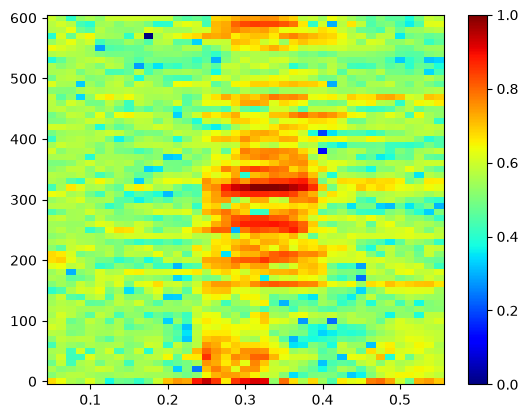

In [8]:
N=700
plt.pcolormesh(t_list, f_list, list_redspectro[N], cmap='jet')
plt.colorbar()
plt.show()

In [9]:
random.seed(0)

In [10]:
# limit green spectro
#list_greenspectro = random.sample(list_greenspectro, len(list_redspectro))

In [11]:
X = np.array(list_redspectro+list_greenspectro)
X = X[:, :, :, np.newaxis]
y = np.concatenate([np.repeat(1, len(list_redspectro)), np.repeat(0, len(list_greenspectro))])

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, stratify=y)

In [13]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1531, 61, 41, 1), (383, 61, 41, 1), (1531,), (383,))

## deep learning

In [14]:
# libraries for deep learning
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout, Conv2D, BatchNormalization, MaxPooling2D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

from tensorflow.keras.utils import plot_model

I0000 00:00:1793596371.284947   29782 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793596371.309819   29782 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793596371.785534   29782 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [15]:
# network & training
keras.utils.set_random_seed(42)

#setting
NB_EPOCH = 500
#NB_CLASSES = 2
#OPTIMIZER = Adam(learning_rate=1e-4)
VERBOSE = 1
INPUT_SHAPE = X.shape[1:]
BATCH_SIZE=64

#callbacks
early_stopping = EarlyStopping(monitor='val_loss', min_delta=0.0, patience=30, verbose=1, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10)

## Building sequential model with CNN (convolutional neural network)

In [16]:
model = Sequential()
k = (3, 3)
# input
model.add(keras.Input(shape=(INPUT_SHAPE)))
# block 1
model.add(Conv2D(64, k, activation='relu', padding='same',
                   name='block1_conv1'))
model.add(Conv2D(64, k, activation='relu', padding='same',
                   name='block1_conv2'))
model.add(Conv2D(64, k, activation='relu', padding='same',
                   name='block1_conv3'))
model.add(MaxPooling2D(pool_size=(2, 2), name='block1_pool'))

#block 2
model.add(Conv2D(128, k, activation='relu', padding='same',
                   name='block2_conv1'))
model.add(Conv2D(128, k, activation='relu', padding='same',
                   name='block2_conv2'))
model.add(Conv2D(128, k, activation='relu', padding='same',
                   name='block2_conv3'))
model.add(MaxPooling2D(pool_size=(3, 2), name='block2_pool'))

#block 3
model.add(Conv2D(256, k, activation='relu', padding='same',
                   name='block3_conv1'))
model.add(Conv2D(256, k, activation='relu', padding='same',
                   name='block3_conv2'))
model.add(Conv2D(256, k, activation='relu', padding='same',
                   name='block3_conv3'))
model.add(MaxPooling2D(pool_size=(2, 2), name='block3_pool'))


# classification block
model.add(Flatten(name='flatten'))
model.add(Dense(128, activation='relu', name='fc1'))
model.add(Dropout(0.25))
model.add(Dense(64, activation='relu', name='fc2'))
model.add(Dropout(0.25))
model.add(Dense(1,  activation='sigmoid', name='predictions'))

W0000 00:00:1793596376.459725   29782 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 61, 41, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 61, 41, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv3 (Conv2D)           │ (None, 61, 41, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 30, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 30, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 30, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv3 (Conv2D)           │ (None, 30, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,746,497 (10.48 MB)

 Trainable params: 2,746,497 (10.48 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
OPTIMIZER = Adam(learning_rate=1e-5)
model.compile(loss='binary_crossentropy', optimizer=OPTIMIZER, metrics=['accuracy'])

In [19]:
hist=model.fit(X_train, y_train, validation_data=(X_test, y_test),
         batch_size=BATCH_SIZE, epochs=NB_EPOCH,
         verbose=VERBOSE,
         callbacks=[early_stopping, reduce_lr])

Epoch 1/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 179ms/step - accuracy: 0.5787 - loss: 0.6926 - val_accuracy: 0.6345 - val_loss: 0.6913 - learning_rate: 1.0000e-05
Epoch 2/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 172ms/step - accuracy: 0.6329 - loss: 0.6893 - val_accuracy: 0.6345 - val_loss: 0.6845 - learning_rate: 1.0000e-05
Epoch 3/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 173ms/step - accuracy: 0.6329 - loss: 0.6759 - val_accuracy: 0.6345 - val_loss: 0.6599 - learning_rate: 1.0000e-05
Epoch 4/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 171ms/step - accuracy: 0.6329 - loss: 0.6583 - val_accuracy: 0.6345 - val_loss: 0.6532 - learning_rate: 1.0000e-05
Epoch 5/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 172ms/step - accuracy: 0.6329 - loss: 0.6615 - val_accuracy: 0.6345 - val_loss: 0.6521 - learning_rate: 1.0000e-05
Epoch 6/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 175ms/step - accuracy: 0.6329 - loss: 0.6557 - val_accuracy: 0.6345 - val_loss: 0.6513 - learning_rate: 1.0000e-05
Epoch 7/500
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 173ms/step - acc

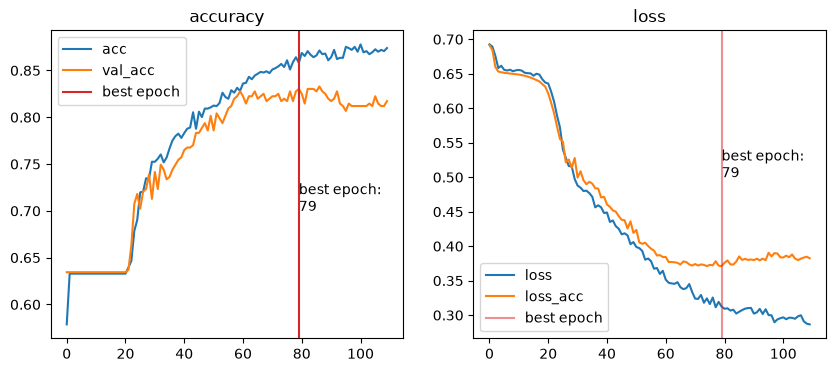

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(hist.history['accuracy'], label = 'acc')
ax[0].plot(hist.history['val_accuracy'], label = 'val_acc')
ax[0].axvline([early_stopping.best_epoch], label='best epoch', color='tab:red')
ax[0].annotate(xy=(early_stopping.best_epoch, .7), text=f'best epoch:\n{early_stopping.best_epoch}')
ax[0].legend()
ax[0].set_title('accuracy')

ax[1].plot(hist.history['loss'], label = 'loss')
ax[1].plot(hist.history['val_loss'], label = 'loss_acc')

ax[1].axvline([early_stopping.best_epoch], label='best epoch', color='tab:red', alpha=0.5)
ax[1].annotate(xy=(early_stopping.best_epoch, .5), text=f'best epoch:\n{early_stopping.best_epoch}')
ax[1].legend()
ax[1].set_title('loss')
plt.show()

In [21]:
# storing a model and weights
model_dir = './model/'

if os.path.exists(model_dir)==False:
    os.mkdir(model_dir)
model.save(model_dir + 'model_pt1.keras')
model.save(model_dir+'model-no_opt_pt1.keras', include_optimizer = False)
model.save_weights(model_dir+'model_weight_pt1.weights.h5')

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score, roc_curve, roc_auc_score

In [24]:
y_pred = model.predict(X_test)
y_pred_bool = (y_pred>=0.5)

dict_score = {}
for key, f in zip(['accuracy', 'precision', 'recall'], [accuracy_score, precision_score, recall_score]):
    dict_score[key] = f(y_test, y_pred_bool)
dict_score['f1'] = f1_score(y_test, y_pred_bool, average='binary')
dict_score['roc_auc'] = roc_auc_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred_bool)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


In [25]:

dict_score

{'accuracy': 0.8302872062663186,
 'precision': 0.7388535031847133,
 'recall': 0.8285714285714286,
 'f1': 0.7811447811447811,
 'roc_auc': 0.9026455026455027}

In [26]:
cm

array([[202,  41],
       [ 24, 116]])

In [27]:
import seaborn as sns

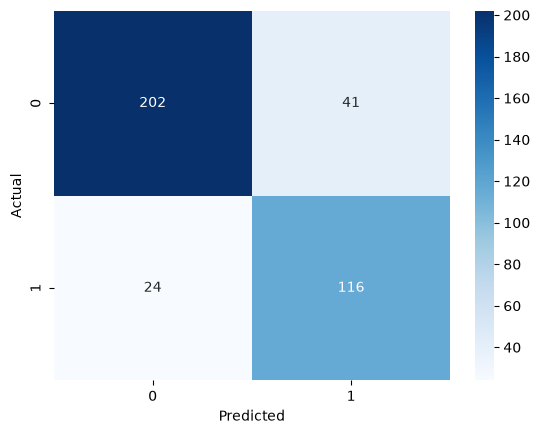

In [28]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [29]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred)

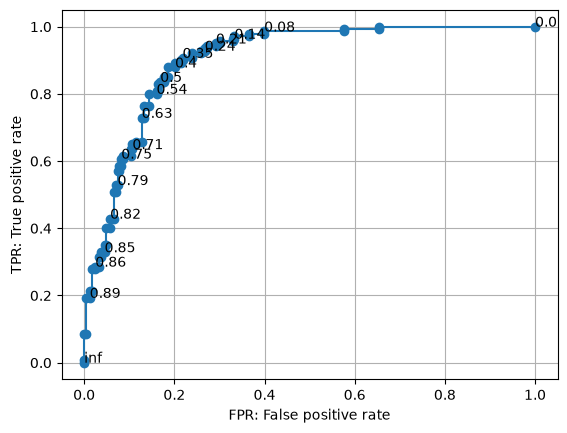

In [30]:
plt.plot(fpr, tpr, marker='o')
for x, y, t in zip(fpr[::5], tpr[::5], thresholds[::5]):
    plt.annotate(xy=(x, y), text=str(round(t, 2)))
plt.xlabel('FPR: False positive rate')
plt.ylabel('TPR: True positive rate')
plt.grid()